# Classificação Binária da Qualidade de Vinhos com Machine Learning

## Finalidade do modelo: apoio à triagem

Este projeto investiga se medições físico-químicas podem ajudar uma vinícola a **priorizar amostras para avaliação sensorial especializada**. O objetivo operacional é reduzir a chance de deixar passar vinhos potencialmente bons (falsos negativos), aceitando que uma parcela das amostras sinalizadas não pertença à classe de alta qualidade (falsos positivos).

A classe positiva é definida conforme o desafio: `quality >= 7`. O modelo produz um score e uma classificação conforme um *threshold* escolhido exclusivamente com previsões *out-of-fold* (OOF) do conjunto de treino. A escolha final será reportada uma única vez no conjunto de teste, que permanece isolado.

**Escopo dos dados:** o arquivo `WineQT.csv` utilizado contém 1.143 registros associados ao recorte de vinhos tintos do conjunto Wine Quality. O arquivo não possui uma variável de cor; portanto, os resultados não devem ser generalizados para vinhos brancos sem validação específica.


## 2. Análise Exploratória de Dados

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

# Define a raiz do projeto a partir do diretório atual ou da pasta do notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WineQT.csv"

try:
    df_raw = pd.read_csv(DATA_PATH)
    print("Arquivo carregado com sucesso: data/raw/WineQT.csv")
    print(f"Dimensões (linhas, colunas): {df_raw.shape}")
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Arquivo não encontrado em '{DATA_PATH}'. Verifique se 'WineQT.csv' está em data/raw/."
    ) from exc

display(df_raw.head(5))
df_raw.info()

Arquivo carregado com sucesso: data/raw/WineQT.csv
Dimensões (linhas, colunas): (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### 2.1 Dicionário de Dados (*Data Dictionary*)

- **`fixed acidity` (*Acidez fixa*):** concentração de ácidos não voláteis que não evaporam facilmente (principalmente ácido tartárico); contribui para a estrutura e sensação de frescor do vinho.
- **`volatile acidity` (*Acidez volátil*):** quantidade de ácidos voláteis (predominantemente ácido acético); em níveis elevados, associa-se a aromas indesejáveis (como vinagre) e perda de qualidade.
- **`citric acid` (*Ácido cítrico*):** presente em pequenas quantidades; pode adicionar frescor e sabor cítrico, além de atuar na estabilidade do vinho.
- **`residual sugar` (*Açúcar residual*):** quantidade de açúcar restante após a fermentação; influencia o dulçor e o corpo da bebida.
- **`chlorides` (*Cloretos*):** teor de sais (como cloreto de sódio) no vinho; níveis altos costumam associar-se a salinidade excessiva e desequilíbrio sensorial.
- **`free sulfur dioxide` (*Dióxido de enxofre livre*):** fração livre do SO₂; parte dela pode estar na forma molecular ativa, contribuindo para a proteção contra oxidação e microrganismos indesejados.
- **`total sulfur dioxide` (*Dióxido de enxofre total*):** soma do SO₂ livre e do SO₂ combinado a outros compostos; indica o nível total de conservante/antioxidante presente.
- **`density` (*Densidade*):** massa por unidade de volume do vinho (próxima à da água, variando conforme teor alcoólico e açúcares/solutos dissolvidos).
- **`pH`:** mede a acidez ativa (escala logarítmica inversa: valores menores indicam maior acidez livre, afetando estabilidade microbiológica e cor).
- **`sulphates` (*Sulfatos*):** concentração de sulfatos medida na amostra. É uma variável distinta das medidas de dióxido de enxofre livre e total; sua associação com a qualidade deve ser interpretada empiricamente, sem presumir que represente o teor de SO₂.
- **`alcohol` (*Teor alcoólico*):** percentual de álcool por volume (% ABV); influencia corpo, percepção sensorial e equilíbrio do vinho.
- **`quality` (*Qualidade original*):** nota sensorial atribuída por especialistas (variável-alvo bruta que será convertida na classificação binária `target`: `1` se `quality >= 7` e `0` se `quality < 7`).
- **`Id` (*Identificador de registro*):** índice/identificador presente no arquivo `WineQT.csv`; não representa característica físico-química do vinho e não deve ser usado como variável preditiva (*feature*) na modelagem.

In [2]:
# 1. Cria a variável-alvo binária conforme definido na Etapa 1 (quality >= 7 -> 1; < 7 -> 0)
df_eda = df_raw.copy()
df_eda["target"] = (df_eda["quality"] >= 7).astype(int)

# 2. Exclui a coluna 'Id' pois é apenas identificador de linha do arquivo, sem significado físico-químico
df_eda = df_eda.drop(columns=["Id"])

# 3. Verifica duplicidades
dup_total = df_eda.duplicated().sum()

print(f"Duplicatas exatas (incluindo quality e target): {dup_total}")

# 4. Distribuição da nota original 'quality' e da variável-alvo binária 'target'
print("\nDistribuição da nota original 'quality':")
display(
    pd.DataFrame({
        "contagem": df_eda["quality"].value_counts().sort_index(),
        "percentual_%": (df_eda["quality"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

print("\nDistribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):")
display(
    pd.DataFrame({
        "contagem": df_eda["target"].value_counts().sort_index(),
        "percentual_%": (df_eda["target"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

# 5. Estatísticas descritivas das variáveis numéricas
print("\nEstatísticas descritivas (excluindo 'target'):")
display(df_eda.drop(columns=["target"]).describe().T.round(4))

Duplicatas exatas (incluindo quality e target): 125

Distribuição da nota original 'quality':


,contagem,percentual_%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40



Distribuição da variável-alvo binária 'target' (0 = <7 | 1 = >=7):


,contagem,percentual_%
target,,
0,984,86.09
1,159,13.91



Estatísticas descritivas (excluindo 'target'):


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


### 2.1.1 Auditoria de perfis físico-químicos repetidos

Antes de decidir pela deduplicação, é importante distinguir registros que repetem o mesmo vetor de atributos físico-químicos de possíveis conflitos de rótulo. A análise abaixo agrupa os registros pelas 11 variáveis preditoras e verifica se um mesmo perfil aparece associado a notas de qualidade diferentes.

**Importante:** encontrar atributos e notas idênticos não prova que as linhas representam a mesma amostra física. Sem metadados de lote ou identificação independente da amostra, essa distinção não pode ser confirmada apenas pelo arquivo.


In [3]:
# Agrupa registros pelos atributos físico-químicos, sem incluir quality/target.
# Assim, também conseguimos detectar o caso de um mesmo perfil associado a rótulos diferentes.
feature_cols = [col for col in df_eda.columns if col not in ["quality", "target"]]

duplicate_profile_summary = (
    df_eda.groupby(feature_cols, dropna=False)
    .agg(
        occurrences=("quality", "size"),
        distinct_quality_scores=("quality", "nunique"),
        quality_scores=("quality", lambda values: tuple(sorted(values.unique()))),
    )
    .reset_index()
)

repeated_profiles = duplicate_profile_summary.query("occurrences > 1").copy()

# Quantidade de linhas excedentes que seriam removidas mantendo a primeira ocorrência.
duplicate_rows_mask = df_eda.duplicated(keep="first")
duplicate_rows_removed = int(duplicate_rows_mask.sum())

duplicate_audit = pd.DataFrame({
    "Indicador": [
        "Total de registros na base",
        "Perfis físico-químicos repetidos",
        "Registros pertencentes a perfis repetidos",
        "Registros excedentes (além da primeira ocorrência)",
        "Perfis repetidos com notas de qualidade conflitantes",
        "Percentual de registros removidos por deduplicação",
    ],
    "Resultado": [
        len(df_eda),
        len(repeated_profiles),
        int(repeated_profiles["occurrences"].sum()),
        int((repeated_profiles["occurrences"] - 1).sum()),
        int((repeated_profiles["distinct_quality_scores"] > 1).sum()),
        f"{duplicate_rows_removed / len(df_eda) * 100:.2f}%",
    ],
})

print("Resumo da auditoria de duplicatas:")
display(duplicate_audit)

print("Registros excedentes removidos por classe:")
removed_by_class = (
    df_eda.loc[duplicate_rows_mask, "target"]
    .value_counts()
    .rename_axis("target")
    .to_frame("registros removidos")
    .sort_index()
)
display(removed_by_class)

print("Distribuição da classe positiva antes e depois da deduplicação:")
class_distribution_comparison = pd.DataFrame({
    "Antes da deduplicação (%)": (
        df_eda["target"].value_counts(normalize=True).sort_index() * 100
    ),
    "Depois da deduplicação (%)": (
        df_eda.loc[~duplicate_rows_mask, "target"].value_counts(normalize=True).sort_index() * 100
    ),
}).round(2)
display(class_distribution_comparison)

print("Frequência dos perfis repetidos:")
display(
    repeated_profiles["occurrences"]
    .value_counts()
    .sort_index()
    .rename_axis("número de ocorrências do perfil")
    .to_frame("quantidade de perfis")
)

print("Exemplos dos perfis repetidos com maior frequência:")
display(
    repeated_profiles
    .sort_values(["occurrences", "distinct_quality_scores"], ascending=[False, False])
    .head(10)
)


Resumo da auditoria de duplicatas:


,Indicador,Resultado
0,Total de registros na base,1143
1,Perfis físico-químicos repetidos,114
2,Registros pertencentes a perfis repetidos,239
3,Registros excedentes (além da primeira ocorrên...,125
4,Perfis repetidos com notas de qualidade confli...,0
5,Percentual de registros removidos por deduplic...,10.94%


Registros excedentes removidos por classe:


,registros removidos
target,
0,103
1,22


Distribuição da classe positiva antes e depois da deduplicação:


,Antes da deduplicação (%),Depois da deduplicação (%)
target,,
0,86.09,86.54
1,13.91,13.46


Frequência dos perfis repetidos:


,quantidade de perfis
número de ocorrências do perfil,
2,105
3,7
4,2


Exemplos dos perfis repetidos com maior frequência:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,occurrences,distinct_quality_scores,quality_scores
137,6.7,0.460,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,4,1,"(6,)"
375,7.5,0.510,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,4,1,"(6,)"
40,6.0,0.500,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,3,1,"(5,)"
230,7.0,0.690,0.07,2.5,0.091,15.0,21.0,0.99572,3.38,0.60,11.3,3,1,"(6,)"
274,7.2,0.360,0.46,2.1,0.074,24.0,44.0,0.99534,3.40,0.85,11.0,3,1,"(7,)"
301,7.2,0.695,0.13,2.0,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,3,1,"(5,)"
476,7.8,0.600,0.26,2.0,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,3,1,"(5,)"
784,9.3,0.360,0.39,1.5,0.080,41.0,55.0,0.99652,3.47,0.73,10.9,3,1,"(6,)"
847,9.9,0.540,0.45,2.3,0.071,16.0,40.0,0.99910,3.39,0.62,9.4,3,1,"(5,)"
13,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,2,1,"(6,)"


**Interpretação da auditoria:** nesta versão do `WineQT.csv`, foram encontrados 114 perfis físico-químicos repetidos, totalizando 239 registros nesses grupos. Manter apenas a primeira ocorrência remove 125 registros excedentes (10,94% da base). Nenhum dos 114 perfis repetidos apresentou notas de qualidade diferentes. A remoção afeta 103 registros da classe 0 e 22 da classe 1; a proporção da classe positiva passa de 13,91% para 13,46%.

Esses resultados sustentam a decisão de evitar que vetores de atributos idênticos apareçam simultaneamente no treino e no teste. Contudo, eles **não comprovam** que as linhas repetidas sejam erros de cadastro ou a mesma amostra física: também podem representar amostras independentes com medições arredondadas iguais. Como o arquivo não contém metadados suficientes para resolver essa questão, a deduplicação será tratada como uma **premissa metodológica conservadora**, e não como uma verdade comprovada sobre a origem dos registros.


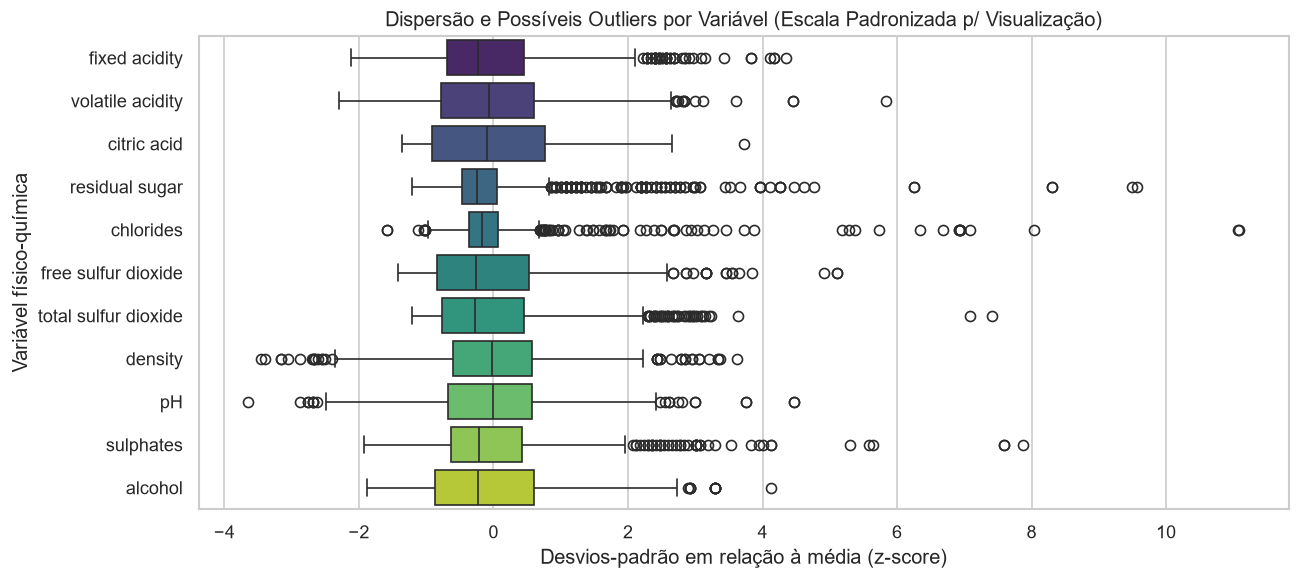

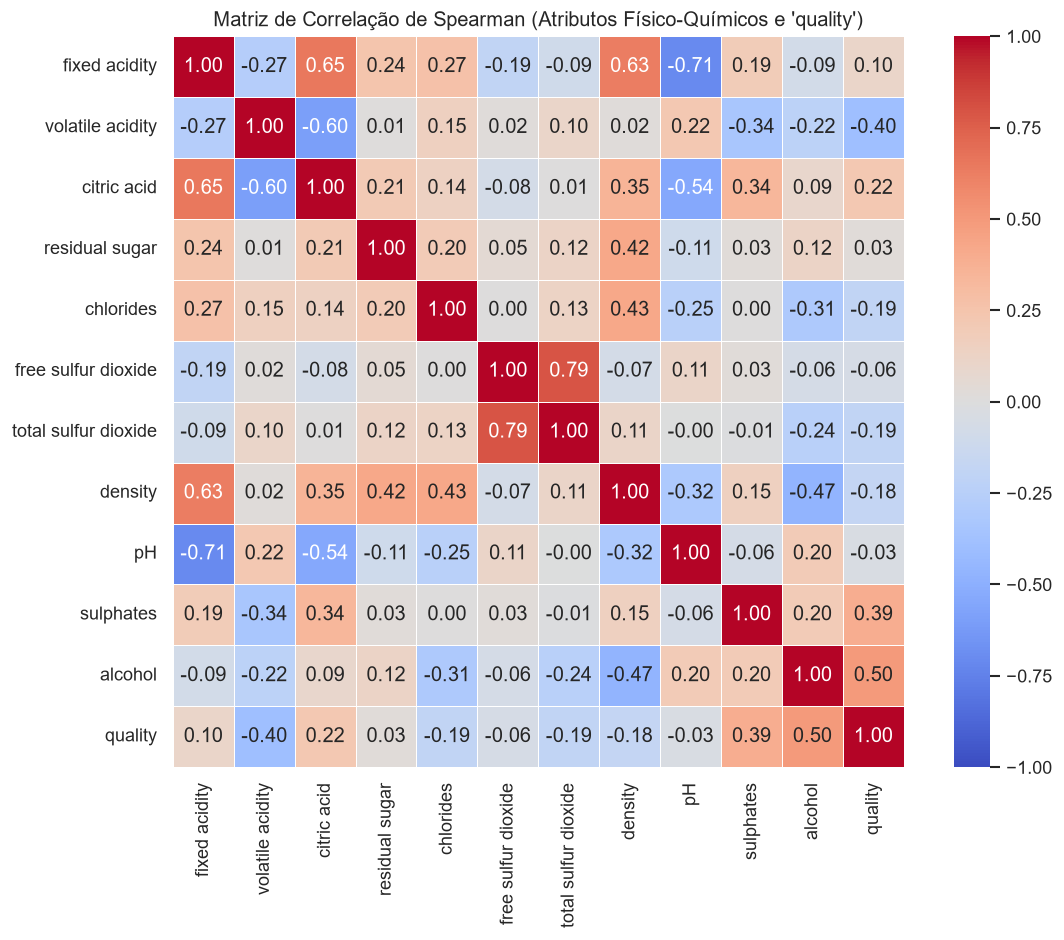

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual consistente
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# 1. Boxplots das variáveis físico-químicas (normalizados por z-score apenas para visualização comparativa)
X_eda = df_eda.drop(columns=["quality", "target"])
X_scaled_vis = (X_eda - X_eda.mean()) / X_eda.std()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=X_scaled_vis, orient="h", palette="viridis", ax=ax)
ax.set_title("Dispersão e Possíveis Outliers por Variável (Escala Padronizada p/ Visualização)", fontsize=12)
ax.set_xlabel("Desvios-padrão em relação à média (z-score)")
ax.set_ylabel("Variável físico-química")
plt.tight_layout()
plt.show()

# 2. Matriz de correlação de Spearman (avalia associações monotônicas e é menos sensível a valores extremos que Pearson)
corr_spearman = df_eda.drop(columns=["target"]).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Matriz de Correlação de Spearman (Atributos Físico-Químicos e 'quality')", fontsize=12)
plt.tight_layout()
plt.show()

### 2.2.1 Quantificação de possíveis outliers e verificações físico-químicas

Os *boxplots* ajudam a visualizar caudas e valores extremos, mas não quantificam quantas observações ultrapassam os limites estatísticos. A tabela seguinte aplica o critério de 1,5 × IQR a cada variável. **Um ponto sinalizado pelo IQR não é automaticamente um erro:** a decisão de manter, transformar ou excluir depende de evidência de inconsistência e do contexto de medição.

Neste projeto, os valores extremos serão mantidos na análise principal quando não houver evidência de erro de registro. Também serão verificadas condições simples de consistência, como `free sulfur dioxide <= total sulfur dioxide`. Valores zero em `citric acid` serão contabilizados, mas não tratados automaticamente como inválidos.


In [5]:
# Quantifica possíveis outliers pelo critério de 1,5 × IQR.
# O critério é um sinalizador exploratório, não uma regra automática de exclusão.
outlier_features = [
    column for column in df_eda.columns
    if column not in ["quality", "target"]
]
outlier_rows = []

for column in outlier_features:
    q1 = df_eda[column].quantile(0.25)
    q3 = df_eda[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df_eda[column] < lower_bound) | (df_eda[column] > upper_bound)

    outlier_rows.append({
        "Variável": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Limite inferior": lower_bound,
        "Limite superior": upper_bound,
        "Possíveis outliers": int(outlier_mask.sum()),
        "Percentual (%)": float(outlier_mask.mean() * 100),
        "Mínimo observado": float(df_eda[column].min()),
        "Máximo observado": float(df_eda[column].max()),
        "Zeros": int(df_eda[column].eq(0).sum()),
    })

df_outlier_summary = (
    pd.DataFrame(outlier_rows)
    .sort_values("Possíveis outliers", ascending=False)
    .reset_index(drop=True)
)
display(df_outlier_summary.round(4))

# Verificações simples de consistência das medições disponíveis.
physical_checks = pd.DataFrame({
    "Verificação": [
        "Registros com SO2 livre maior que SO2 total",
        "Registros com SO2 total igual a zero",
        "Registros com acidez fixa igual a zero",
        "Registros com ácido cítrico igual a zero",
        "Valores ausentes nas variáveis físico-químicas",
    ],
    "Quantidade": [
        int((df_eda["free sulfur dioxide"] > df_eda["total sulfur dioxide"]).sum()),
        int(df_eda["total sulfur dioxide"].eq(0).sum()),
        int(df_eda["fixed acidity"].eq(0).sum()),
        int(df_eda["citric acid"].eq(0).sum()),
        int(df_eda[outlier_features].isna().sum().sum()),
    ],
})
display(physical_checks)

print(
    "Decisão de pré-processamento: os valores sinalizados pelo IQR serão mantidos "
    "na análise principal, pois o critério estatístico isolado não comprova erro de medição."
)


,Variável,Q1,Q3,IQR,Limite inferior,Limite superior,Possíveis outliers,Percentual (%),Mínimo observado,Máximo observado,Zeros
0,residual sugar,1.9000,2.6000,0.7000,0.8500,3.6500,110,9.6238,0.9000,15.5000,0
1,chlorides,0.0700,0.0900,0.0200,0.0400,0.1200,77,6.7367,0.0120,0.6110,0
2,fixed acidity,7.1000,9.1000,2.0000,4.1000,12.1000,44,3.8495,4.6000,15.9000,0
3,sulphates,0.5500,0.7300,0.1800,0.2800,1.0000,43,3.7620,0.3300,2.0000,0
4,total sulfur dioxide,21.0000,61.0000,40.0000,-39.0000,121.0000,40,3.4996,6.0000,289.0000,0
5,density,0.9956,0.9978,0.0023,0.9922,1.0013,36,3.1496,0.9901,1.0037,0
6,pH,3.2050,3.4000,0.1950,2.9125,3.6925,20,1.7498,2.7400,4.0100,0
7,free sulfur dioxide,7.0000,21.0000,14.0000,-14.0000,42.0000,18,1.5748,1.0000,68.0000,0
8,volatile acidity,0.3925,0.6400,0.2475,0.0213,1.0112,14,1.2248,0.1200,1.5800,0
9,alcohol,9.5000,11.1000,1.6000,7.1000,13.5000,12,1.0499,8.4000,14.9000,0


,Verificação,Quantidade
0,Registros com SO2 livre maior que SO2 total,0
1,Registros com SO2 total igual a zero,0
2,Registros com acidez fixa igual a zero,0
3,Registros com ácido cítrico igual a zero,99
4,Valores ausentes nas variáveis físico-químicas,0


Decisão de pré-processamento: os valores sinalizados pelo IQR serão mantidos na análise principal, pois o critério estatístico isolado não comprova erro de medição.


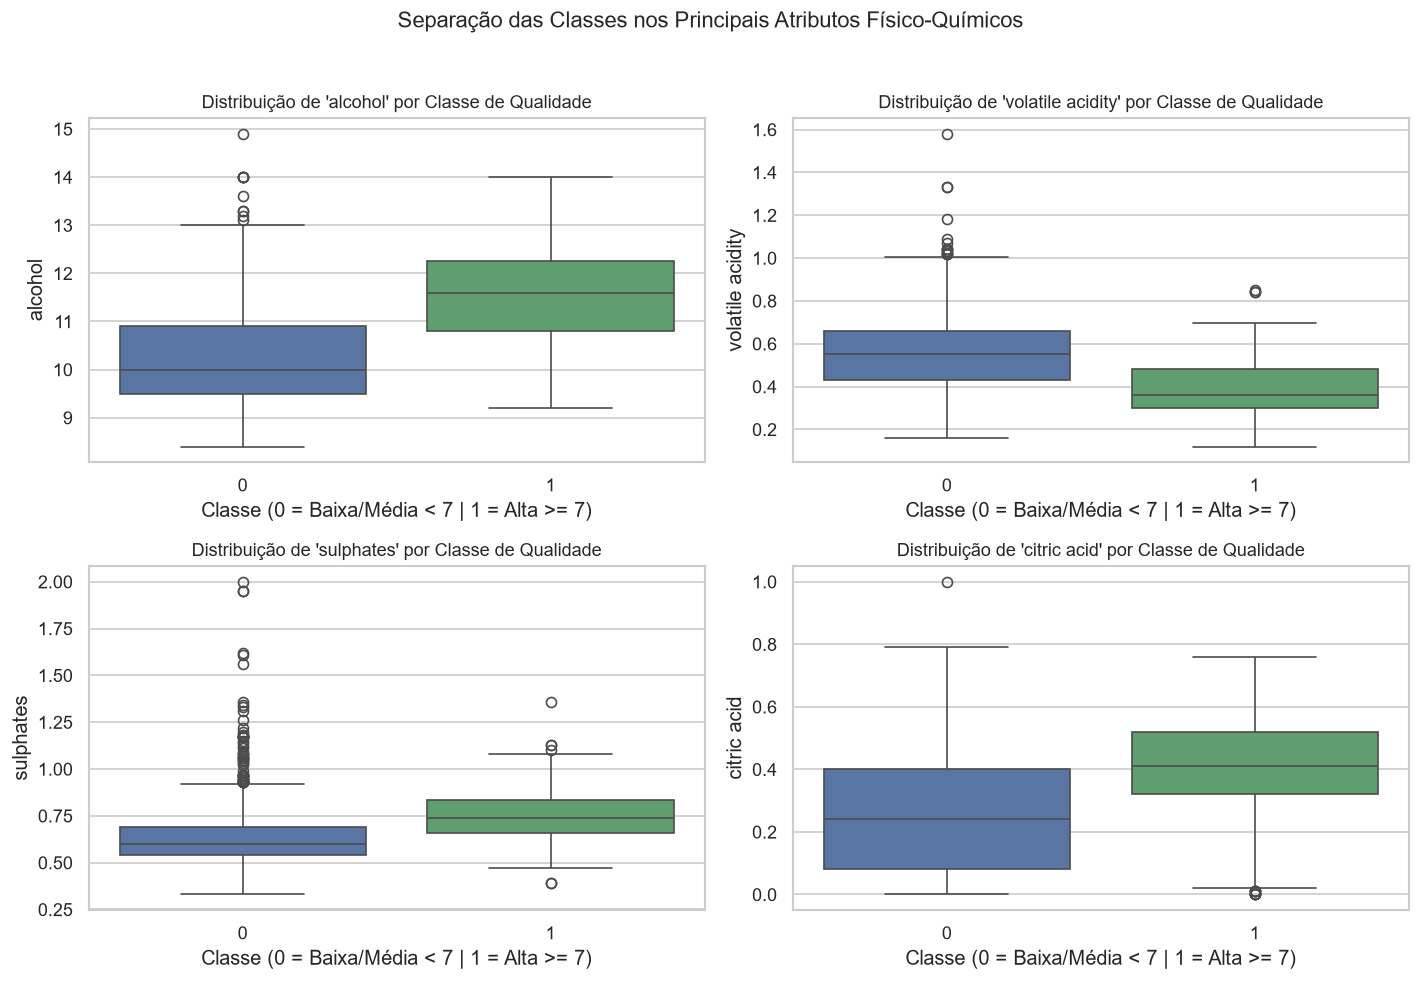

In [6]:
# Comparação de 4 atributos selecionados pela associação com a nota original 'quality' (Spearman)

top_features = ["alcohol", "volatile acidity", "sulphates", "citric acid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, top_features):
    sns.boxplot(
        data=df_eda,
        x="target",
        y=col,
        hue="target",
        palette={0: "#4C72B0", 1: "#55A868"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Distribuição de '{col}' por Classe de Qualidade", fontsize=11)
    ax.set_xlabel("Classe (0 = Baixa/Média < 7 | 1 = Alta >= 7)")
    ax.set_ylabel(col)

plt.suptitle("Separação das Classes nos Principais Atributos Físico-Químicos", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Conclusões da Análise Exploratória de Dados (EDA)

A investigação exploratória orientou as decisões de pré-processamento e modelagem:

1. **Integridade e estrutura:** a base possui 1.143 registros, 11 variáveis físico-químicas, a nota `quality` e o identificador `Id`. Não foram encontrados valores ausentes. `Id` foi removido por não representar uma propriedade físico-química.
2. **Duplicidades:** foram identificados 114 perfis físico-químicos repetidos, com 125 linhas excedentes. Nenhum perfil repetido apresentou notas conflitantes. A deduplicação será tratada como uma premissa metodológica, não como prova de que os registros eram a mesma amostra física.
3. **Desbalanceamento:** antes da deduplicação, 86,09% dos registros pertenciam à classe baixa/média e 13,91% à classe alta. Após a deduplicação, a proporção positiva é 13,46%.
4. **Outliers:** o critério de 1,5 × IQR sinaliza valores extremos em algumas variáveis, especialmente `residual sugar`, `chlorides`, `fixed acidity` e `sulphates`. Esses sinalizadores não demonstram erro de medição. Como não há metadados para confirmar erros e os valores são mantidos como observações do dataset, a decisão principal é preservá-los e reportar a limitação.
5. **Consistência físico-química:** não foram encontrados casos em que `free sulfur dioxide` fosse maior que `total sulfur dioxide`. Há observações com `citric acid = 0`; elas serão mantidas, pois zero não foi considerado automaticamente inválido.
6. **Associações com `quality` (Spearman):** destacam-se `alcohol` (+0,50), `volatile acidity` (-0,40), `sulphates` (+0,39) e `citric acid` (+0,22). Essas associações não demonstram causalidade.
7. **Sobreposição entre classes:** as distribuições se sobrepõem; nenhuma característica isolada determina a nota sensorial. A classificação é multivariada.

**Escopo:** o arquivo `WineQT.csv` é um recorte associado a vinhos tintos. O dataset original da UCI disponibiliza conjuntos separados para vinho tinto e branco; portanto, este estudo não valida a aplicação em vinhos brancos. Fonte original: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).


## 3. Pré-processamento e *Feature Engineering*

### 3.1 Preparação dos dados

Nesta etapa, vamos separar os dados em treino e teste. O conjunto de teste ficará guardado para a avaliação final. A divisão será estratificada para preservar a proporção das classes.

In [7]:
from sklearn.model_selection import train_test_split

# Valor fixo para que a divisão possa ser reproduzida.
RANDOM_STATE = 2024

# Mantemos uma ocorrência de cada registro exatamente repetido.
df_model = df_eda.drop_duplicates().reset_index(drop=True)
print(f"Linhas antes da deduplicação: {len(df_eda)}")
print(f"Linhas após a deduplicação: {len(df_model)}")

X = df_model.drop(columns=["quality", "target"])
y = df_model["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Treino: {X_train.shape} | Classe positiva: {y_train.mean():.2%}")
print(f"Teste:  {X_test.shape} | Classe positiva: {y_test.mean():.2%}")

Linhas antes da deduplicação: 1143
Linhas após a deduplicação: 1018
Treino: (814, 11) | Classe positiva: 13.51%
Teste:  (204, 11) | Classe positiva: 13.24%


### 3.2 Criação de novas variáveis (*Feature Engineering*)

Vamos manter duas variáveis derivadas, construídas a partir de relações simples entre medições já existentes. A mesma função será reutilizada no script de predição, para que os dados futuros recebam o mesmo tratamento.

In [8]:
from src.features import add_domain_features, RAW_FEATURES, MODEL_FEATURES

# Confere se o arquivo contém as 11 variáveis originais esperadas.
if list(X_train.columns) != RAW_FEATURES:
    raise ValueError("Os nomes ou a ordem das variáveis originais não correspondem ao esperado.")

X_train_fe = add_domain_features(X_train)
X_test_fe = add_domain_features(X_test)

print(f"Variáveis originais: {X_train.shape[1]}")
print(f"Variáveis após Feature Engineering: {X_train_fe.shape[1]}")
display(X_train_fe[["free_sulfur_ratio", "volatile_to_fixed_acidity"]].describe().T.round(4))

Variáveis originais: 11
Variáveis após Feature Engineering: 13


,count,mean,std,min,25%,50%,75%,max
free_sulfur_ratio,814.0,0.378,0.1492,0.0357,0.2582,0.3750,0.4750,0.8571
volatile_to_fixed_acidity,814.0,0.068,0.0291,0.0135,0.0446,0.0661,0.0865,0.2080


### 3.3 Decisões do pré-processamento

1. **Deduplicação:** mantivemos uma ocorrência de cada registro exatamente repetido antes da divisão. A base não permite afirmar se esses registros representam a mesma amostra física ou medições coincidentes.
2. **Divisão estratificada:** 80% dos dados foram destinados ao treino e 20% ao teste. O teste não será utilizado para escolher o modelo nem o *threshold*.
3. **Outliers:** os valores sinalizados pelo IQR serão mantidos, pois esse critério identifica valores extremos, mas não comprova erro de medição.
4. **Escalonamento:** será aplicado dentro dos *pipelines* dos modelos que dependem da escala, como Regressão Logística, KNN e SVM.
5. **Feature Engineering:** foram criadas `free_sulfur_ratio` e `volatile_to_fixed_acidity`. Vamos comparar os modelos utilizando essas 13 variáveis.

## 4. Desenvolvimento e comparação dos modelos

### 4.1 Modelo de referência (*baseline*)

Antes de comparar algoritmos, vamos avaliar um classificador simples que sempre prevê a classe mais frequente. Ele funciona como referência: os modelos desenvolvidos precisam superar esse resultado.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Cinco divisões estratificadas: cada fold preserva aproximadamente a proporção das classes.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Average Precision é a métrica principal por causa do desbalanceamento.
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
}

baseline = DummyClassifier(strategy="most_frequent")
baseline_scores = cross_validate(
    baseline, X_train_fe, y_train, cv=cv, scoring=scoring, n_jobs=-1
)

df_baseline = pd.DataFrame([{
    "Modelo": "Dummy (classe mais frequente)",
    "Average Precision média": baseline_scores["test_average_precision"].mean(),
    "AP desvio-padrão": baseline_scores["test_average_precision"].std(),
    "ROC-AUC média": baseline_scores["test_roc_auc"].mean(),
}]).round(4)
display(df_baseline)

,Modelo,Average Precision média,AP desvio-padrão,ROC-AUC média
0,Dummy (classe mais frequente),0.1351,0.0003,0.5


### 4.2 Comparação exploratória de cinco famílias de algoritmos

Vamos comparar Regressão Logística, KNN, SVM com kernel RBF, Random Forest e Gradient Boosting. Para manter a comparação simples, todos receberão o mesmo conjunto de 13 variáveis e serão avaliados pela mesma validação cruzada estratificada de cinco folds.

O `StandardScaler` ficará dentro dos *pipelines* dos modelos sensíveis à escala. Também vamos usar `predict_proba` no SVM para obter *scores* que possam ser utilizados na seleção posterior do *threshold*.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

candidate_models = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7)),
    ]),
    "SVM RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1, class_weight=None
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

comparison_rows = []
for model_name, model in candidate_models.items():
    scores = cross_validate(
        model,
        X_train_fe,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    comparison_rows.append({
        "Modelo": model_name,
        "Average Precision média": scores["test_average_precision"].mean(),
        "AP desvio-padrão": scores["test_average_precision"].std(),
        "ROC-AUC média": scores["test_roc_auc"].mean(),
    })

df_models_cv = (
    pd.DataFrame(comparison_rows)
    .sort_values("Average Precision média", ascending=False)
    .reset_index(drop=True)
)
display(df_models_cv.round(4))

,Modelo,Average Precision média,AP desvio-padrão,ROC-AUC média
0,SVM RBF,0.5948,0.0627,0.8603
1,Random Forest,0.5823,0.0529,0.8880
2,Regressão Logística,0.5552,0.0697,0.8866
3,Gradient Boosting,0.5479,0.0704,0.8752
4,KNN,0.4669,0.0869,0.8165


### 4.3 Ajuste simples dos três modelos mais promissores

A comparação anterior serve para selecionar os três candidatos com maior Average Precision média. Vamos realizar uma busca pequena de hiperparâmetros somente nesses três modelos. Como queremos verificar especificamente a alternativa de balanceamento do Random Forest, garantiremos que ele esteja entre os três candidatos aprofundados, mesmo que sua posição preliminar fique fora do grupo dos três primeiros.

Também incluiremos `class_weight="balanced_subsample"` na busca do Random Forest. Assim podemos verificar se o balanceamento ajuda a reconhecer a classe minoritária sem criar uma etapa adicional de modelagem.

In [11]:
from sklearn.model_selection import GridSearchCV

# Grades pequenas: testamos poucas opções relevantes para cada algoritmo.
parameter_grids = {
    "Regressão Logística": {
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    "KNN": {
        "model__n_neighbors": [5, 9, 13],
        "model__weights": ["uniform", "distance"],
    },
    "SVM RBF": {
        "model__C": [0.5, 1.0, 5.0],
        "model__gamma": ["scale", 0.1],
    },
    "Random Forest": {
        "n_estimators": [200],
        "max_depth": [4, 5, 6],
        "min_samples_leaf": [1, 3],
        "class_weight": [None, "balanced_subsample"],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3],
    },
}

# Escolhemos os três modelos mais bem colocados na comparação exploratória.
top3_models = df_models_cv.head(3)["Modelo"].tolist()
if "Random Forest" not in top3_models:
    top3_models = top3_models[:2] + ["Random Forest"]
print("Modelos selecionados para ajuste:", top3_models)

searches = {}
tuning_rows = []

for model_name in top3_models:
    grid = GridSearchCV(
        estimator=candidate_models[model_name],
        param_grid=parameter_grids[model_name],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    grid.fit(X_train_fe, y_train)
    searches[model_name] = grid

    tuning_rows.append({
        "Modelo": model_name,
        "Melhor AP na validação cruzada": grid.best_score_,
        "Desvio-padrão da AP": grid.cv_results_["std_test_score"][grid.best_index_],
        "Melhores parâmetros": str(grid.best_params_),
    })

df_tuning_results = (
    pd.DataFrame(tuning_rows)
    .sort_values("Melhor AP na validação cruzada", ascending=False)
    .reset_index(drop=True)
)
display(df_tuning_results.round(4))

# O melhor candidato é aquele com maior Average Precision média na busca.
chosen_model_name = df_tuning_results.loc[0, "Modelo"]
final_search = searches[chosen_model_name]
best_final_model = final_search.best_estimator_
chosen_dataset_name = "13 Features (FE)"


print(f"Modelo selecionado: {chosen_model_name}")
print("Melhores parâmetros:", final_search.best_params_)

Modelos selecionados para ajuste: ['SVM RBF', 'Random Forest', 'Regressão Logística']


c:\Users\diego\Projetos\wine-quality-classification\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Modelo,Melhor AP na validação cruzada,Desvio-padrão da AP,Melhores parâmetros
0,Random Forest,0.6179,0.0628,"{'class_weight': 'balanced_subsample', 'max_de..."
1,SVM RBF,0.6033,0.0624,"{'model__C': 1.0, 'model__gamma': 0.1}"
2,Regressão Logística,0.5669,0.0771,"{'model__C': 0.1, 'model__class_weight': 'bala..."


Modelo selecionado: Random Forest
Melhores parâmetros: {'class_weight': 'balanced_subsample', 'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 200}


In [12]:
rf_results = searches["Random Forest"].cv_results_

df_rf_diagnostic = pd.DataFrame({
    "max_depth": [
        params["max_depth"] for params in rf_results["params"]
    ],
    "min_samples_leaf": [
        params["min_samples_leaf"] for params in rf_results["params"]
    ],
    "class_weight": [
        params["class_weight"] for params in rf_results["params"]
    ],
    "AP treinamento": rf_results["mean_train_score"],
    "AP validação": rf_results["mean_test_score"],
    "DP validação": rf_results["std_test_score"],
})

display(
    df_rf_diagnostic.sort_values(
        "AP validação", ascending=False
    ).round(4)
)

,max_depth,min_samples_leaf,class_weight,AP treinamento,AP validação,DP validação
9,5,3,balanced_subsample,0.8979,0.6179,0.0628
11,6,3,balanced_subsample,0.9452,0.6128,0.0797
4,6,1,NaN,0.9725,0.6041,0.0475
5,6,3,NaN,0.9378,0.6035,0.0600
10,6,1,balanced_subsample,0.9647,0.6017,0.0779
6,4,1,balanced_subsample,0.8450,0.6001,0.0747
7,4,3,balanced_subsample,0.8329,0.5991,0.0758
0,4,1,NaN,0.8506,0.5965,0.0512
8,5,1,balanced_subsample,0.9106,0.5959,0.0697
3,5,3,NaN,0.8960,0.5938,0.0581


### 4.4 Decisão da etapa de modelagem

A comparação exploratória considera cinco famílias de algoritmos. Para evitar buscas demoradas e pouco didáticas, o ajuste de hiperparâmetros é realizado somente nos três candidatos mais bem colocados.

A configuração final é escolhida pela maior Average Precision média na validação cruzada. O conjunto de teste não participa dessa escolha e será utilizado apenas na avaliação final.

## 5. Avaliação do modelo e escolha do *threshold*

### 5.1 Diagnóstico simples de *overfitting*

O `GridSearchCV` registra o desempenho em cada fold tanto nos dados usados para ajustar o modelo quanto nos dados de validação. Vamos comparar essas médias para identificar sinais de ajuste excessivo.

Uma diferença grande entre AP de treino e AP de validação pode indicar *overfitting*. Como os hiperparâmetros são escolhidos usando a própria validação cruzada, essa comparação é diagnóstica; a avaliação no conjunto de teste continua sendo a referência final de generalização.

In [13]:
best_index = final_search.best_index_
cv_results = final_search.cv_results_

mean_train_ap = cv_results["mean_train_score"][best_index]
mean_valid_ap = cv_results["mean_test_score"][best_index]

df_overfit_diagnostic = pd.DataFrame([{
    "Modelo selecionado": chosen_model_name,
    "AP média no treino dos folds": mean_train_ap,
    "AP média na validação dos folds": mean_valid_ap,
    "Diferença treino - validação": mean_train_ap - mean_valid_ap,
}])
display(df_overfit_diagnostic.round(4))

print("Uma diferença elevada é um sinal de possível overfitting, não uma prova isolada.")

,Modelo selecionado,AP média no treino dos folds,AP média na validação dos folds,Diferença treino - validação
0,Random Forest,0.8979,0.6179,0.28


Uma diferença elevada é um sinal de possível overfitting, não uma prova isolada.


### 5.2 Escolha do *threshold* para triagem com previsões OOF

Como o objetivo é **triagem**, queremos reduzir a quantidade de vinhos de alta qualidade que o modelo deixa de identificar. Por isso, vamos escolher o *threshold* usando o **F2-Score**, que dá mais peso ao Recall do que à Precision.

As previsões *out-of-fold* (OOF) são geradas dentro do conjunto de treino: cada observação recebe uma previsão de um modelo que não foi ajustado naquela observação. Os hiperparâmetros já foram escolhidos por validação cruzada na mesma partição de treino; por isso, esta é uma regra interna de seleção do threshold, não uma validação independente adicional. O conjunto de teste permanece intocado e será usado para a avaliação final.

A busca por F2 é uma regra simples e alinhada ao objetivo de triagem. O threshold escolhido será uma recomendação inicial; a capacidade da equipe de avaliar amostras e o custo dos falsos positivos ainda precisam ser discutidos com a área de negócio.

In [14]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, fbeta_score

# Cada linha recebe uma previsão de um modelo que não foi ajustado naquela linha.
oof_probabilities = cross_val_predict(
    clone(best_final_model),
    X_train_fe,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

threshold_values = np.round(np.arange(0.05, 0.96, 0.01), 2)
threshold_rows = []

for threshold in threshold_values:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, oof_predictions, zero_division=0),
        "Recall": recall_score(y_train, oof_predictions, zero_division=0),
        "F2-Score": fbeta_score(y_train, oof_predictions, beta=2, zero_division=0),
        "Amostras sinalizadas": int(oof_predictions.sum()),
    })

df_threshold_optimization_oof = pd.DataFrame(threshold_rows)
# Em caso de empate no F2, preferimos o maior Recall e depois a maior Precision.
df_threshold_optimization_oof = df_threshold_optimization_oof.sort_values(
    ["F2-Score", "Recall", "Precision"], ascending=False
).reset_index(drop=True)

best_threshold_row = df_threshold_optimization_oof.iloc[0]
chosen_threshold = float(best_threshold_row["Threshold"])

df_threshold_scenarios_oof = df_threshold_optimization_oof[
    df_threshold_optimization_oof["Threshold"].isin([0.50, 0.60, 0.70])
].copy()
df_threshold_scenarios_oof = pd.concat([
    pd.DataFrame([best_threshold_row]), df_threshold_scenarios_oof
]).drop_duplicates(subset=["Threshold"]).reset_index(drop=True)

display(df_threshold_scenarios_oof.round(4))
print(f"Threshold recomendado pelo F2: {chosen_threshold:.2f}")
print(f"Precision OOF: {best_threshold_row['Precision']:.2%}")
print(f"Recall OOF: {best_threshold_row['Recall']:.2%}")
print(f"F2 OOF: {best_threshold_row['F2-Score']:.4f}")
print(f"Amostras sinalizadas no treino (OOF): {int(best_threshold_row['Amostras sinalizadas'])}")

,Threshold,Precision,Recall,F2-Score,Amostras sinalizadas
0,0.39,0.4272,0.8273,0.6968,213.0
1,0.50,0.4777,0.6818,0.6281,157.0
2,0.60,0.5534,0.5182,0.5249,103.0
3,0.70,0.6567,0.4000,0.4339,67.0


Threshold recomendado pelo F2: 0.39
Precision OOF: 42.72%
Recall OOF: 82.73%
F2 OOF: 0.6968
Amostras sinalizadas no treino (OOF): 213


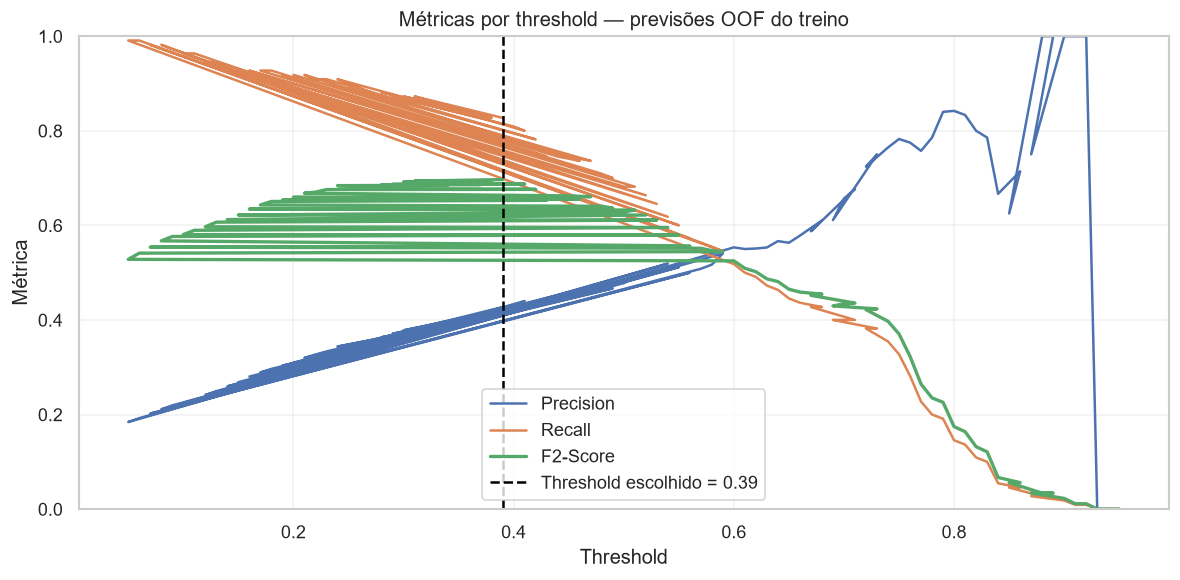

In [15]:
# Gráfico simples para visualizar como Precision, Recall e F2 mudam com o threshold.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["Precision"], label="Precision")
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["Recall"], label="Recall")
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["F2-Score"], label="F2-Score", linewidth=2)
ax.axvline(chosen_threshold, color="black", linestyle="--", label=f"Threshold escolhido = {chosen_threshold:.2f}")
ax.set(title="Métricas por threshold — previsões OOF do treino", xlabel="Threshold", ylabel="Métrica")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 Avaliação final no conjunto de teste

Agora vamos ajustar o melhor modelo em todo o conjunto de treino e avaliar uma única vez no conjunto de teste. O *threshold* recomendado já foi definido anteriormente com as previsões OOF do treino.

Também mostraremos 0,50, 0,60 e 0,70 como análise de sensibilidade. Esses cenários ajudam a visualizar a troca entre Precision e Recall, mas **não serão usados para mudar a escolha depois de observar o teste**.

Resumo do modelo no conjunto de teste:


,Modelo,Average Precision (teste),ROC-AUC (teste),Observações no teste,Positivas no teste,Prevalência positiva no teste
0,Random Forest,0.6122,0.8845,204,27,0.1324


Comparação dos cenários de threshold (o recomendado foi escolhido antes de consultar o teste):


,Cenário,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,Amostras sinalizadas,VP,FP,FN,VN
0,Recomendado (F2),0.39,0.7745,0.3443,0.7778,0.4773,0.6213,61,21,40,6,137
1,Padrão,0.50,0.7990,0.3600,0.6667,0.4675,0.5696,50,18,32,9,145
2,Intermediário,0.60,0.8480,0.4444,0.5926,0.5079,0.5556,36,16,20,11,157
3,Conservador,0.70,0.8873,0.6111,0.4074,0.4889,0.4365,18,11,7,16,170


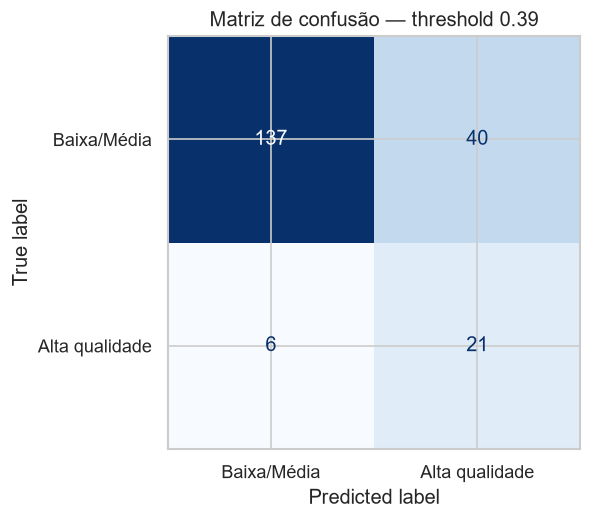

In [16]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

# O GridSearchCV já ajustou o melhor estimador em todo o conjunto de treino.
X_train_final = X_train_fe.copy()
X_test_final = X_test_fe.copy()

# Scores do conjunto de teste: são calculados uma única vez.
y_test_scores = best_final_model.predict_proba(X_test_final)[:, 1]
test_average_precision = average_precision_score(y_test, y_test_scores)
test_roc_auc = roc_auc_score(y_test, y_test_scores)
positive_prevalence_test = float(y_test.mean())

# Threshold recomendado mais três referências para análise de sensibilidade.
threshold_scenarios = [
    ("Recomendado (F2)", chosen_threshold),
    ("Padrão", 0.50),
    ("Intermediário", 0.60),
    ("Conservador", 0.70),
]

test_rows = []
for scenario_name, threshold in threshold_scenarios:
    predictions = (y_test_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_rows.append({
        "Cenário": scenario_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "F2-Score": fbeta_score(y_test, predictions, beta=2, zero_division=0),
        "Amostras sinalizadas": int(predictions.sum()),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    })

df_test_results = pd.DataFrame(test_rows)
df_test_summary = pd.DataFrame([{
    "Modelo": chosen_model_name,
    "Average Precision (teste)": test_average_precision,
    "ROC-AUC (teste)": test_roc_auc,
    "Observações no teste": len(y_test),
    "Positivas no teste": int(y_test.sum()),
    "Prevalência positiva no teste": positive_prevalence_test,
}])

print("Resumo do modelo no conjunto de teste:")
display(df_test_summary.round(4))
print("Comparação dos cenários de threshold (o recomendado foi escolhido antes de consultar o teste):")
display(df_test_results.round(4))

# Matriz de confusão do threshold recomendado.
y_test_pred = (y_test_scores >= chosen_threshold).astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["Baixa/Média", "Alta qualidade"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Matriz de confusão — threshold {chosen_threshold:.2f}")
plt.tight_layout()
plt.show()

### 5.4 Curvas ROC e Precision–Recall

As curvas mostram o comportamento do modelo em vários thresholds. A curva Precision–Recall é especialmente útil aqui porque a classe de alta qualidade é minoritária. A linha horizontal representa a prevalência da classe positiva no teste.

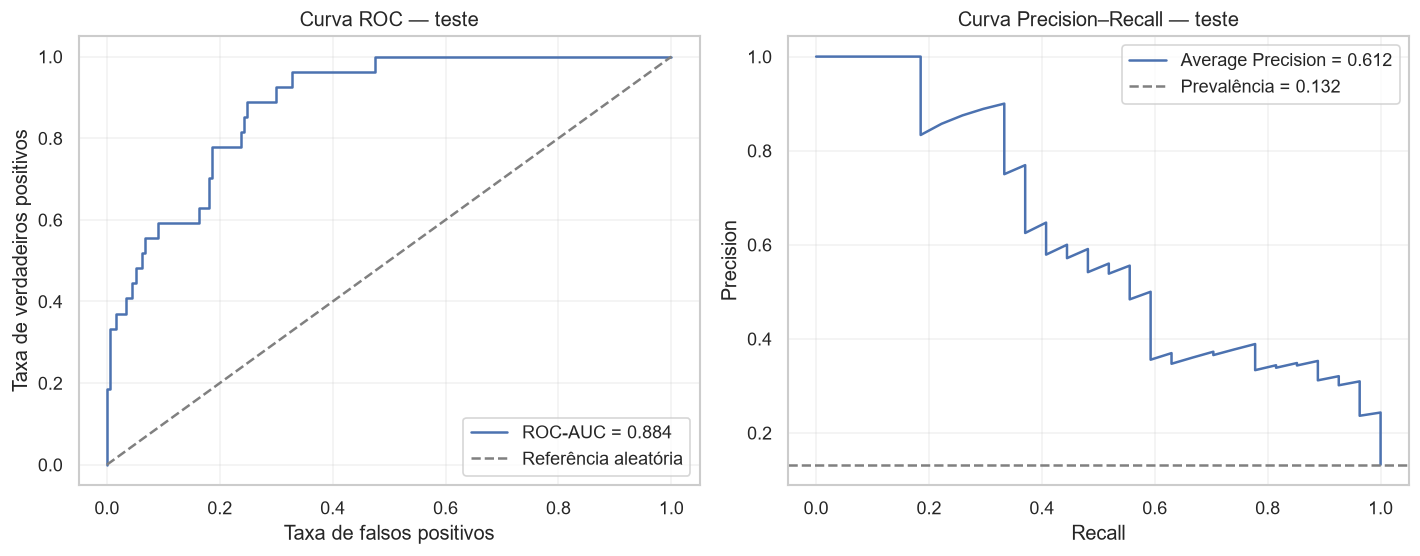

In [17]:
from sklearn.metrics import roc_curve, precision_recall_curve

roc_fpr, roc_tpr, _ = roc_curve(y_test, y_test_scores)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, y_test_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(roc_fpr, roc_tpr, label=f"ROC-AUC = {test_roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referência aleatória")
axes[0].set(title="Curva ROC — teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
axes[0].legend(); axes[0].grid(alpha=0.25)

axes[1].plot(pr_recall, pr_precision, label=f"Average Precision = {test_average_precision:.3f}")
axes[1].axhline(positive_prevalence_test, linestyle="--", color="gray", label=f"Prevalência = {positive_prevalence_test:.3f}")
axes[1].set(title="Curva Precision–Recall — teste", xlabel="Recall", ylabel="Precision")
axes[1].legend(); axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 5.5 Síntese da avaliação

- **Modelo:** escolhido pela maior Average Precision média na busca com validação cruzada, entre os três candidatos selecionados na comparação exploratória.
- **Threshold:** escolhido no conjunto de treino por F2, com maior peso para Recall.
- **Teste:** utilizado somente depois de finalizar a escolha do modelo e do threshold. Os resultados dos cenários alternativos são apresentados apenas como análise de sensibilidade.
- **Interpretação:** para triagem, um Recall maior significa encontrar mais vinhos da classe positiva, mas normalmente aumenta a quantidade de amostras encaminhadas à avaliação sensorial. A recomendação precisa considerar a capacidade de avaliação da empresa.

## 6. Interpretação do modelo — *Permutation Feature Importance*

A importância por permutação mede quanto a métrica do modelo cai quando embaralhamos uma variável de cada vez. Vamos utilizar Average Precision e o conjunto de teste. Essa análise é interpretativa: não será usada para remover variáveis nem para retreinar o modelo.

In [18]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    estimator=best_final_model,
    X=X_test_final,
    y=y_test,
    scoring="average_precision",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

df_permutation_importance = pd.DataFrame({
    "Variável": X_test_final.columns,
    "Importância média (queda na AP)": permutation_result.importances_mean,
    "Desvio-padrão das permutações": permutation_result.importances_std,
}).sort_values("Importância média (queda na AP)", ascending=False).reset_index(drop=True)

display(df_permutation_importance.round(4))

,Variável,Importância média (queda na AP),Desvio-padrão das permutações
0,sulphates,0.1389,0.0329
1,alcohol,0.1363,0.0532
2,volatile acidity,0.0735,0.0511
3,citric acid,0.0644,0.0371
4,total sulfur dioxide,0.0505,0.0353
5,volatile_to_fixed_acidity,0.0414,0.0409
6,density,0.0250,0.0326
7,residual sugar,0.0170,0.0118
8,free_sulfur_ratio,0.0137,0.0225
9,fixed acidity,0.0043,0.0120


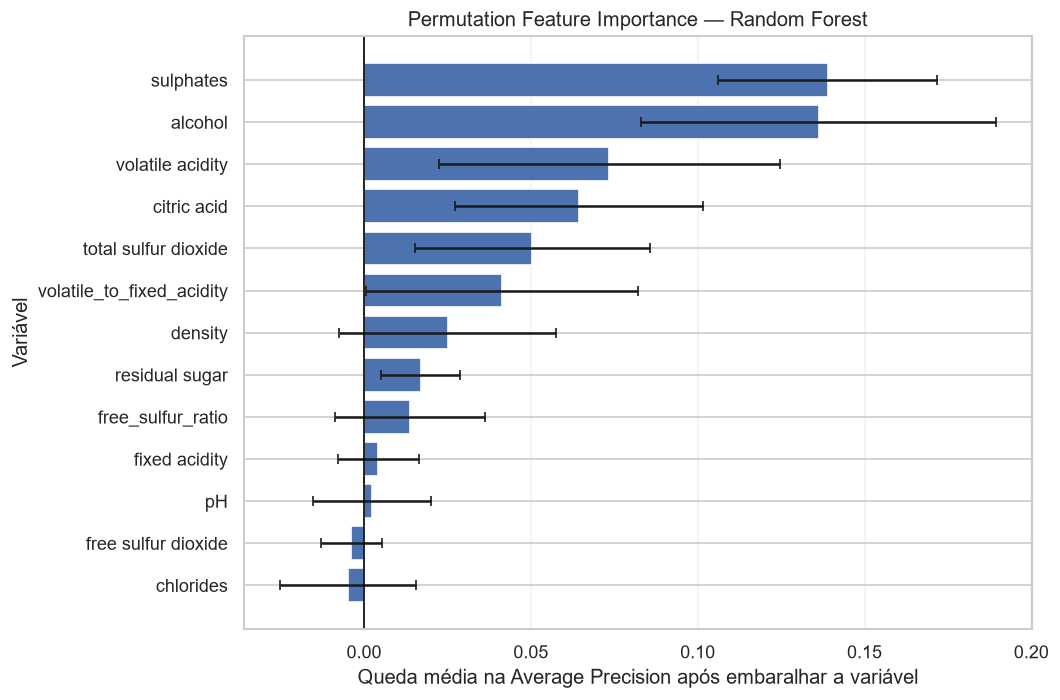

In [19]:
plot_pfi = df_permutation_importance.sort_values(
    "Importância média (queda na AP)", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    plot_pfi["Variável"],
    plot_pfi["Importância média (queda na AP)"],
    xerr=plot_pfi["Desvio-padrão das permutações"],
    capsize=3,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title(f"Permutation Feature Importance — {chosen_model_name}")
ax.set_xlabel("Queda média na Average Precision após embaralhar a variável")
ax.set_ylabel("Variável")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 6.1 Como interpretar os resultados

Uma queda maior na Average Precision sugere que o modelo depende mais daquela informação para ordenar as amostras. Importância próxima de zero indica pouca contribuição individual observada nesta avaliação. Valores negativos podem ocorrer por variação da amostra ou porque a permutação não prejudicou o desempenho.

A importância preditiva não demonstra causalidade. Além disso, variáveis correlacionadas podem compartilhar informação: ao embaralhar uma delas, outras podem continuar oferecendo sinais semelhantes ao modelo. A acidez volátil pode apresentar correlação com a nota original e, ainda assim, ter baixa importância individual, justamente porque o modelo também utiliza outras medidas relacionadas à acidez. A análise é exploratória e deve ser interpretada com cautela, pois o conjunto de teste contém poucas observações positivas.

## 7. Conclusões gerais, implicações para o negócio e limitações

### 7.1 Síntese técnica

O estudo utiliza o arquivo `WineQT.csv`, um recorte associado a vinhos tintos, e transforma a nota sensorial em uma classificação binária: alta qualidade (`quality >= 7`) e baixa/média qualidade (`quality < 7`). Após a análise exploratória e a deduplicação adotada como premissa metodológica, os dados foram separados de forma estratificada em treino e teste.

Foram comparadas cinco famílias de algoritmos. Os três candidatos com maior Average Precision média na validação cruzada receberam uma busca pequena de hiperparâmetros. A seleção final e o threshold foram definidos sem consultar o conjunto de teste. O resultado efetivo será apresentado nas tabelas da execução deste notebook.

### 7.2 Recomendação de uso

A finalidade proposta é **triagem de amostras para avaliação sensorial especializada**. O threshold é selecionado pelo F2 no conjunto de treino, dando mais peso ao Recall. Isso tende a encaminhar mais amostras para avaliação, inclusive algumas que não pertencem à classe de alta qualidade. A escolha deve ser confrontada com a capacidade operacional da equipe.

### 7.3 Possíveis implicações para a produção

Os resultados exploratórios podem orientar hipóteses de monitoramento:

- **Acidez volátil:** acompanhar sua evolução por lote e investigar medições elevadas com a equipe de enologia, considerando sua associação conhecida com características sensoriais indesejáveis.
- **Teor alcoólico e densidade:** observar em conjunto os lotes com perfis semelhantes aos associados pelo modelo à classe de maior qualidade.
- **Sulfatos:** acompanhar a variável como um indicador preditivo identificado pelo modelo, interpretando-a em conjunto com as demais medições.
- **Proporção de SO₂ livre/total:** monitorar a relação como informação complementar sobre o perfil de dióxido de enxofre.

Esses pontos são hipóteses de monitoramento, não recomendações automáticas para alterar a produção. Devem ser avaliados por profissionais de enologia.

### 7.4 Limitações

- O conjunto de teste contém poucas observações positivas; pequenas mudanças de classificação afetam Precision e Recall.
- O arquivo utilizado corresponde a um recorte de vinhos tintos. Não foi validado para vinhos brancos.
- A deduplicação é uma premissa conservadora; a base não permite confirmar se perfis repetidos representam a mesma amostra física.
- O intervalo entre desempenho no treino e validação pode indicar ajuste excessivo (*overfitting*).
- Os scores de `predict_proba` não foram avaliados quanto à calibração e não devem ser interpretados como probabilidades perfeitamente calibradas.
- As importâncias das variáveis são preditivas, não causais, e podem ser afetadas por correlações entre atributos.
- Os custos de falsos positivos e falsos negativos e a capacidade diária de avaliação sensorial ainda precisam ser definidos com a empresa.

### 7.5 Próximos passos

1. Testar o threshold recomendado em novos lotes com avaliação sensorial registrada.
2. Acompanhar Recall, Precision e quantidade de amostras encaminhadas à equipe.
3. Reavaliar o modelo em outras safras, produtores e equipamentos.
4. Realizar um estudo específico antes de aplicar o modelo a vinhos brancos.

## 8. Exportação do modelo com Pickle

Vamos salvar o modelo final e as informações necessárias para utilizá-lo em novos dados. O estimador foi treinado somente com a partição de treino; o conjunto de teste permaneceu separado.

O arquivo também guarda o threshold recomendado, para que o script de predição possa usá-lo automaticamente quando o usuário não informar outro valor.

> **Segurança:** carregue somente arquivos Pickle criados por você ou por uma fonte confiável.

In [20]:
import pickle
import platform
import sklearn

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "wine_quality_model.pkl"

model_bundle = {
    "artifact_version": "3.0",
    "model": best_final_model,
    "model_name": chosen_model_name,
    "dataset_name": chosen_dataset_name,
    "raw_feature_columns": list(RAW_FEATURES),
    "model_feature_columns": list(MODEL_FEATURES),
    "target_definition": "1 = quality >= 7; 0 = quality < 7",
    "best_params": final_search.best_params_,
    "recommended_threshold": float(chosen_threshold),
    "threshold_selection_metric": "F2 maximized on OOF predictions from training data",
    "threshold_oof_precision": float(best_threshold_row["Precision"]),
    "threshold_oof_recall": float(best_threshold_row["Recall"]),
    "threshold_oof_f2": float(best_threshold_row["F2-Score"]),
    "business_purpose": "triage for sensory evaluation",
    "training_rows": int(len(X_train_final)),
    "test_rows": int(len(X_test_final)),
    "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),
}

with MODEL_PATH.open("wb") as model_file:
    pickle.dump(model_bundle, model_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Modelo salvo em: {MODEL_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Modelo: {chosen_model_name}")
print(f"Threshold recomendado: {chosen_threshold:.2f}")
print(f"Scikit-learn: {sklearn.__version__}")

Modelo salvo em: models/wine_quality_model.pkl
Modelo: Random Forest
Threshold recomendado: 0.39
Scikit-learn: 1.9.1


## 9. Demonstração do fluxo de predição com dados em CSV

Vamos conferir se o modelo salvo pelo Pickle produz os mesmos scores do estimador em memória. Depois criaremos um pequeno CSV de demonstração e aplicaremos o threshold recomendado e três valores de referência.

As linhas de demonstração são selecionadas apenas para exercitar o programa. Elas não constituem uma nova avaliação independente do modelo.

### 9.1 Conferência do modelo salvo

Carregamos o pacote Pickle e verificamos se ele mantém o mesmo resultado do estimador utilizado na avaliação.

In [21]:
from src.predict import load_model_bundle, predict_dataframe

loaded_model_bundle = load_model_bundle(MODEL_PATH)
scores_in_memory = best_final_model.predict_proba(X_test_final)[:, 1]
scores_from_pickle = loaded_model_bundle["model"].predict_proba(X_test_final)[:, 1]

if not np.allclose(scores_in_memory, scores_from_pickle, rtol=0, atol=1e-12):
    raise AssertionError("Os scores do modelo carregado diferem dos scores do estimador avaliado.")

print("Pickle carregado com sucesso.")
print("Os scores do modelo salvo coincidem com os do estimador avaliado.")
print(f"Threshold recomendado salvo: {loaded_model_bundle['recommended_threshold']:.2f}")

Pickle carregado com sucesso.
Os scores do modelo salvo coincidem com os do estimador avaliado.
Threshold recomendado salvo: 0.39


### 9.2 Criação de um CSV demonstrativo

Selecionamos amostras do conjunto de teste em faixas de score diferentes, quando disponíveis. O arquivo terá apenas um identificador e as 11 variáveis físico-químicas de entrada; não terá `quality` nem `target`.

In [22]:
score_by_index = pd.Series(scores_from_pickle, index=X_test.index)

demo_bands = {
    "abaixo_050": score_by_index < 0.50,
    "entre_050_060": (score_by_index >= 0.50) & (score_by_index < 0.60),
    "entre_060_070": (score_by_index >= 0.60) & (score_by_index < 0.70),
    "a_partir_070": score_by_index >= 0.70,
}

selected_indices = []
selected_band_names = []
for band_name, band_mask in demo_bands.items():
    candidates = score_by_index.loc[band_mask]
    if candidates.empty:
        print(f"Aviso: não há amostra na faixa {band_name}.")
        continue
    # Escolhe uma amostra próxima do centro da faixa para facilitar a demonstração.
    reference = {
        "abaixo_050": 0.40,
        "entre_050_060": 0.55,
        "entre_060_070": 0.65,
        "a_partir_070": 0.75,
    }[band_name]
    selected_index = (candidates - reference).abs().idxmin()
    selected_indices.append(selected_index)
    selected_band_names.append(band_name)

if not selected_indices:
    raise ValueError("Nenhuma amostra foi encontrada para a demonstração.")

demo_input = X_test.loc[selected_indices, RAW_FEATURES].copy().reset_index(drop=True)
demo_input.insert(0, "sample_id", [f"DEMO_{name.upper()}" for name in selected_band_names])

EXAMPLE_DIR = PROJECT_ROOT / "data" / "examples"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)
DEMO_INPUT_PATH = EXAMPLE_DIR / "threshold_demo_from_holdout.csv"
demo_input.to_csv(DEMO_INPUT_PATH, index=False, encoding="utf-8-sig")

print(f"CSV demonstrativo salvo em: {DEMO_INPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}")
display(demo_input)

CSV demonstrativo salvo em: data/examples/threshold_demo_from_holdout.csv


,sample_id,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,DEMO_ABAIXO_050,11.5,0.590,0.59,2.6,0.087,13.0,49.0,0.99880,3.18,0.65,11.0
1,DEMO_ENTRE_050_060,6.4,0.380,0.14,2.2,0.038,15.0,25.0,0.99514,3.44,0.65,11.1
2,DEMO_ENTRE_060_070,5.9,0.395,0.13,2.4,0.056,14.0,28.0,0.99362,3.62,0.67,12.4
3,DEMO_A_PARTIR_070,10.4,0.240,0.46,1.8,0.075,6.0,21.0,0.99760,3.25,1.02,10.8


### 9.3 Comparação dos thresholds

Vamos aplicar o threshold recomendado e os três cenários de referência ao mesmo CSV. Os scores devem permanecer iguais; apenas a classe prevista pode mudar.

In [23]:
demo_comparison = demo_input[["sample_id"]].copy()
reference_scores = None

prediction_dir = PROJECT_ROOT / "results" / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

for scenario_name, threshold in threshold_scenarios:
    result = predict_dataframe(demo_input, loaded_model_bundle, threshold=threshold)
    current_scores = result["score_modelo_alta_qualidade"].to_numpy()

    if reference_scores is None:
        reference_scores = current_scores
        demo_comparison["Score do modelo"] = current_scores
    elif not np.allclose(reference_scores, current_scores, rtol=0, atol=1e-12):
        raise AssertionError("Os scores mudaram quando somente o threshold foi alterado.")

    column_name = f"{scenario_name} ({threshold:.2f})"
    demo_comparison[column_name] = result["classificacao_prevista"]
    file_slugs = {
        "Recomendado (F2)": "recommended",
        "Padrão": "padrao",
        "Intermediário": "intermediario",
        "Conservador": "conservador",
    }
    file_label = file_slugs[scenario_name]
    result.to_csv(prediction_dir / f"threshold_demo_{file_label}.csv", index=False, encoding="utf-8-sig")

display(demo_comparison.round(4))
demo_comparison.to_csv(prediction_dir / "threshold_demo_comparison.csv", index=False, encoding="utf-8-sig")
print("Validação concluída: os scores permaneceram constantes nos diferentes thresholds.")

,sample_id,Score do modelo,Recomendado (F2) (0.39),Padrão (0.50),Intermediário (0.60),Conservador (0.70)
0,DEMO_ABAIXO_050,0.4104,Alta qualidade,Baixa/Média qualidade,Baixa/Média qualidade,Baixa/Média qualidade
1,DEMO_ENTRE_050_060,0.5564,Alta qualidade,Alta qualidade,Baixa/Média qualidade,Baixa/Média qualidade
2,DEMO_ENTRE_060_070,0.6474,Alta qualidade,Alta qualidade,Alta qualidade,Baixa/Média qualidade
3,DEMO_A_PARTIR_070,0.7412,Alta qualidade,Alta qualidade,Alta qualidade,Alta qualidade


Validação concluída: os scores permaneceram constantes nos diferentes thresholds.


### 9.4 Como executar pelo Windows PowerShell

Com o ambiente virtual ativado e na raiz do projeto:

**Usar o threshold recomendado salvo no Pickle:**

```powershell
python -m src.predict --input data/examples/novos_vinhos_exemplo.csv
```

**Informar manualmente outro threshold:**

```powershell
python -m src.predict --input data/examples/novos_vinhos_exemplo.csv --threshold 0.50
```

O threshold pode variar entre 0 e 1. Ele altera a regra de classificação, não os scores produzidos pelo modelo.

## 10. Exportação de gráficos e métricas para o repositório

Nesta seção vamos salvar tabelas e gráficos principais em `results/metrics/` e `results/figures/`. Assim, os resultados podem ser consultados sem executar novamente o notebook.

In [24]:
from pathlib import Path

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

metric_tables = {
  
    "outlier_summary.csv": df_outlier_summary,
    "baseline_model.csv": df_baseline,
    "model_comparison_cv.csv": df_models_cv,
    "hyperparameter_search.csv": df_tuning_results,
    "random_forest_configurations.csv": df_rf_diagnostic,
    "overfitting_diagnostic.csv": df_overfit_diagnostic,
    "threshold_optimization_oof.csv": df_threshold_optimization_oof,
    "threshold_scenarios_oof.csv": df_threshold_scenarios_oof,
    "threshold_test_scenarios.csv": df_test_results,
    "test_summary.csv": df_test_summary,
    "permutation_feature_importance.csv": df_permutation_importance,
}

for filename, table in metric_tables.items():
    table.to_csv(METRICS_DIR / filename, index=False, encoding="utf-8-sig")

# Matriz de correlação da EDA.
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    df_eda.drop(columns=["target"]).corr(method="spearman"),
    annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
)
ax.set_title("Matriz de correlação de Spearman")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_spearman_correlation.png", dpi=160, bbox_inches="tight")
plt.close(fig)

# Curvas ROC e Precision-Recall.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(roc_fpr, roc_tpr, label=f"ROC-AUC = {test_roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="Curva ROC — teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(pr_recall, pr_precision, label=f"AP = {test_average_precision:.3f}")
axes[1].axhline(positive_prevalence_test, linestyle="--", color="gray", label="Prevalência positiva")
axes[1].set(title="Curva Precision–Recall — teste", xlabel="Recall", ylabel="Precision")
axes[1].legend(); axes[1].grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "roc_and_precision_recall_test.png", dpi=160, bbox_inches="tight")
plt.close(fig)

# Matriz de confusão do conjunto de teste.
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Baixa/Média", "Alta qualidade"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title(
    f"Matriz de confusão — teste (threshold {chosen_threshold:.2f})"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "confusion_matrix_test.png",
    dpi=160,
    bbox_inches="tight"
)

plt.close(fig)


# Importância individual por permutação.
plot_pfi = df_permutation_importance.sort_values("Importância média (queda na AP)", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_pfi["Variável"], plot_pfi["Importância média (queda na AP)"],
        xerr=plot_pfi["Desvio-padrão das permutações"], capsize=3)
ax.axvline(0, color="black", linewidth=1)
ax.set(title=f"Permutation Feature Importance — {chosen_model_name}",
       xlabel="Queda média na Average Precision", ylabel="Variável")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "permutation_feature_importance.png", dpi=160, bbox_inches="tight")
plt.close(fig)

# Trade-off no conjunto de treino (OOF), sem consultar o teste para escolher o threshold.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["Precision"], label="Precision")
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["Recall"], label="Recall")
ax.plot(df_threshold_optimization_oof["Threshold"], df_threshold_optimization_oof["F2-Score"], label="F2-Score")
ax.axvline(chosen_threshold, color="black", linestyle="--", label=f"Escolhido = {chosen_threshold:.2f}")
ax.set(title="Trade-off de métricas — OOF do treino", xlabel="Threshold", ylabel="Métrica")
ax.set_ylim(0, 1); ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "threshold_tradeoff_oof.png", dpi=160, bbox_inches="tight")
plt.close(fig)

print(f"Tabelas salvas em: {METRICS_DIR.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Gráficos salvos em: {FIGURES_DIR.relative_to(PROJECT_ROOT).as_posix()}")

Tabelas salvas em: results/metrics
Gráficos salvos em: results/figures
